In [2]:
pip install tensorflow matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [3]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

# Step 1: Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

# Step 2: Normalize pixel values between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Convert labels into one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

# CIFAR-10 class names
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Step 3: Display sample images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 4: Create the CNN model
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Step 5: Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Step 6: Train the CNN
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Step 7: Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Step 8: Predict the classes
predictions = model.predict(x_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

# Step 9: Print the classification report
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

# Step 10: Plot accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Step 11: Display sample predictions
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


112967680/170498071 ━━━━━━━━━━━━━━━━━━━━ 25:06 26us/step

ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


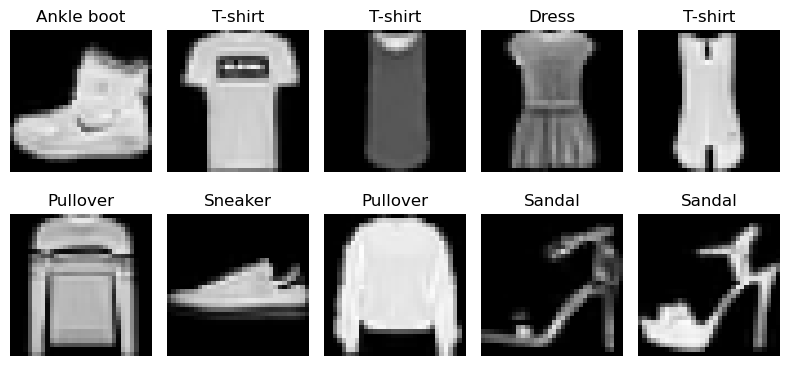

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 39ms/step - accuracy: 0.7920 - loss: 0.5730 - val_accuracy: 0.8635 - val_loss: 0.3649
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 41ms/step - accuracy: 0.8616 - loss: 0.3840 - val_accuracy: 0.8785 - val_loss: 0.3291
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 35s 41ms/step - accuracy: 0.8782 - loss: 0.3333 - val_accuracy: 0.8850 - val_loss: 0.3024
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 40ms/step - accuracy: 0.8897 - loss: 0.3024 - val_accuracy: 0.8950 - val_loss: 0.2756
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 40ms/step - accuracy: 0.8973 - loss: 0.2800 - val_accuracy: 0.8992 - val_loss: 0.2635
Test Loss: 0.2737
Test Accuracy: 89.85 %
              precision    recall  f1-score   support

     T-shirt       0.86      0.83      0.85      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.86      0.83      0.84      1000
       Dress       0.88      0.92      0.90      1000
        Coat       0.81      0.87      0.84

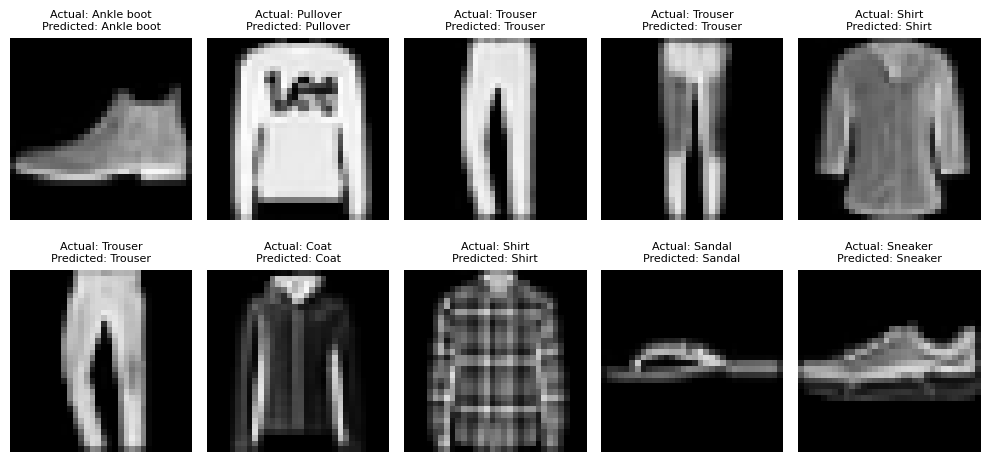

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

# Step 1: Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Step 2: Resize images to 32 x 32
x_train = tf.image.resize(
    x_train[..., np.newaxis], (32, 32)
).numpy()

x_test = tf.image.resize(
    x_test[..., np.newaxis], (32, 32)
).numpy()

# Convert grayscale to 3 channels
x_train = np.repeat(x_train, 3, axis=-1)
x_test = np.repeat(x_test, 3, axis=-1)

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Step 3: Display sample images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 4: Create CNN
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Step 5: Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 6: Train model
model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Step 7: Evaluate model
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Step 8: Classification report
predictions = model.predict(x_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Step 9: Display sample predictions
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[y_pred[i]]}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()